In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
print('libraries import successfully')

libraries import successfully


In [3]:
df = pd.read_csv("noaa - 5000.csv")

In [ ]:
df.head()

,stn,wban,date,year,mo,da,temp,count_temp,dewp,count_dewp,...,flag_min,prcp,flag_prcp,sndp,fog,rain_drizzle,snow_ice_pellets,hail,thunder,tornado_funnel_cloud
0,10020,99999,2025-07-04,2025,7,4,42.1,4,38.5,4,...,NaN,0.0,I,999.9,0,0,0,0,0,0
1,10020,99999,2025-04-30,2025,4,30,7.6,4,3.8,4,...,NaN,0.0,I,999.9,0,0,0,0,0,0
2,10020,99999,2025-04-19,2025,4,19,2.7,4,-2.5,4,...,NaN,0.0,I,999.9,0,0,0,0,0,0
3,10020,99999,2025-04-20,2025,4,20,4.2,4,-1.0,4,...,NaN,0.0,I,999.9,0,0,0,0,0,0
4,10020,99999,2025-03-05,2025,3,5,14.4,4,10.0,4,...,NaN,0.0,I,999.9,0,0,0,0,0,0


In [ ]:
#step 1
df['date'] = pd.to_datetime(df['date'])

In [ ]:
df.head()

,stn,wban,date,year,mo,da,temp,count_temp,dewp,count_dewp,...,flag_min,prcp,flag_prcp,sndp,fog,rain_drizzle,snow_ice_pellets,hail,thunder,tornado_funnel_cloud
0,10020,99999,2025-07-04,2025,7,4,42.1,4,38.5,4,...,NaN,0.0,I,999.9,0,0,0,0,0,0
1,10020,99999,2025-04-30,2025,4,30,7.6,4,3.8,4,...,NaN,0.0,I,999.9,0,0,0,0,0,0
2,10020,99999,2025-04-19,2025,4,19,2.7,4,-2.5,4,...,NaN,0.0,I,999.9,0,0,0,0,0,0
3,10020,99999,2025-04-20,2025,4,20,4.2,4,-1.0,4,...,NaN,0.0,I,999.9,0,0,0,0,0,0
4,10020,99999,2025-03-05,2025,3,5,14.4,4,10.0,4,...,NaN,0.0,I,999.9,0,0,0,0,0,0


In [ ]:
#step 2
date_interval = pd.date_range(start='2025-01-01', periods=365, freq='D')
print(date_interval[:5])
print(f'dates: {len(date_interval)}')

DatetimeIndex(['2025-01-01', '2025-01-02', '2025-01-03', '2025-01-04',
               '2025-01-05'],
              dtype='datetime64[us]', freq='D')
dates: 365


In [ ]:
np.random.seed(42)
temperatures = 55+25*np.sin(2*np.pi*np.arange(365)/365)+np.random.normal(0,4,365)
df_temp=pd.DataFrame({'TEMP':temperatures}, index=date_interval)
df_temp.index.name='date'
print(df_temp.head())
print(f'\nIndex type:{type(df_temp.index)} - now its a DatetimeIndex')

                 TEMP
date                 
2025-01-01  56.986857
2025-01-02  54.877277
2025-01-03  58.451294
2025-01-04  62.382611
2025-01-05  55.783447

Index type:<class 'pandas.DatetimeIndex'> - now its a DatetimeIndex


In [ ]:
#step 3
# Weekly average temperature (already done)
weekly_avg = df_temp.resample("W").mean()
print("Weekly Average temperatures:")
print(weekly_avg.head())

# Monthly average temperature
monthly_avg = df_temp.resample("MS").mean()
print("\nMonthly temperatures:")
print(monthly_avg)

Weekly Average temperatures:
                 TEMP
date                 
2025-01-05  57.696297
2025-01-12  59.147906
2025-01-19  58.199975
2025-01-26  63.115859
2025-02-02  66.715223

Monthly temperatures:
                 TEMP
date                 
2025-01-01  60.502482
2025-02-01  71.592281
2025-03-01  78.799268
2025-04-01  79.002090
2025-05-01  72.688258
2025-06-01  63.297443
2025-07-01  49.703725
2025-08-01  37.786533
2025-09-01  30.873302
2025-10-01  31.294825
2025-11-01  38.186855
2025-12-01  48.068367


In [ ]:
#step 4
# Creates a new column in YOUR df_temp
df_temp['30_day_MA'] = df_temp['TEMP'].rolling(window=30, min_periods=15).mean()

print(df_temp.head(35))

                 TEMP  30_day_MA
date                            
2025-01-01  56.986857        NaN
2025-01-02  54.877277        NaN
2025-01-03  58.451294        NaN
2025-01-04  62.382611        NaN
2025-01-05  55.783447        NaN
2025-01-06  56.212572        NaN
2025-01-07  63.894394        NaN
2025-01-08  61.074940        NaN
2025-01-09  56.554072        NaN
2025-01-10  61.027961        NaN
2025-01-11  57.428658        NaN
2025-01-12  57.842749        NaN
2025-01-13  61.095462        NaN
2025-01-14  52.894917        NaN
2025-01-15  54.067148  58.038290
2025-01-16  59.134682  58.106815
2025-01-17  57.747629  58.085686
2025-01-18  63.469050  58.384762
2025-01-19  58.990934  58.416666
2025-01-20  57.382527  58.364959
2025-01-21  69.300668  58.885707
2025-01-22  62.938798  59.069938
2025-01-23  64.513226  59.306603
2025-01-24  58.942592  59.291436
2025-01-25  62.859669  59.434165
2025-01-26  65.873530  59.681833
2025-01-27  61.215416  59.738633
2025-01-28  67.708526  60.023272
2025-01-29

In [ ]:
#step 5
# Create a DataFrame from the daily series
# Extract calendar attributes
df_temp["month"] = df_temp.index.month
df_temp["month_name"] = df_temp.index.month_name()
df_temp["day_of_week"] = df_temp.index.dayofweek
df_temp["day_name"] = df_temp.index.day_name()
df_temp["year"] = df_temp.index.year

print(df_temp.head())

                 TEMP  30_day_MA  month month_name  day_of_week   day_name  \
date                                                                         
2025-01-01  56.986857        NaN      1    January            2  Wednesday   
2025-01-02  54.877277        NaN      1    January            3   Thursday   
2025-01-03  58.451294        NaN      1    January            4     Friday   
2025-01-04  62.382611        NaN      1    January            5   Saturday   
2025-01-05  55.783447        NaN      1    January            6     Sunday   

            year  
date              
2025-01-01  2025  
2025-01-02  2025  
2025-01-03  2025  
2025-01-04  2025  
2025-01-05  2025  


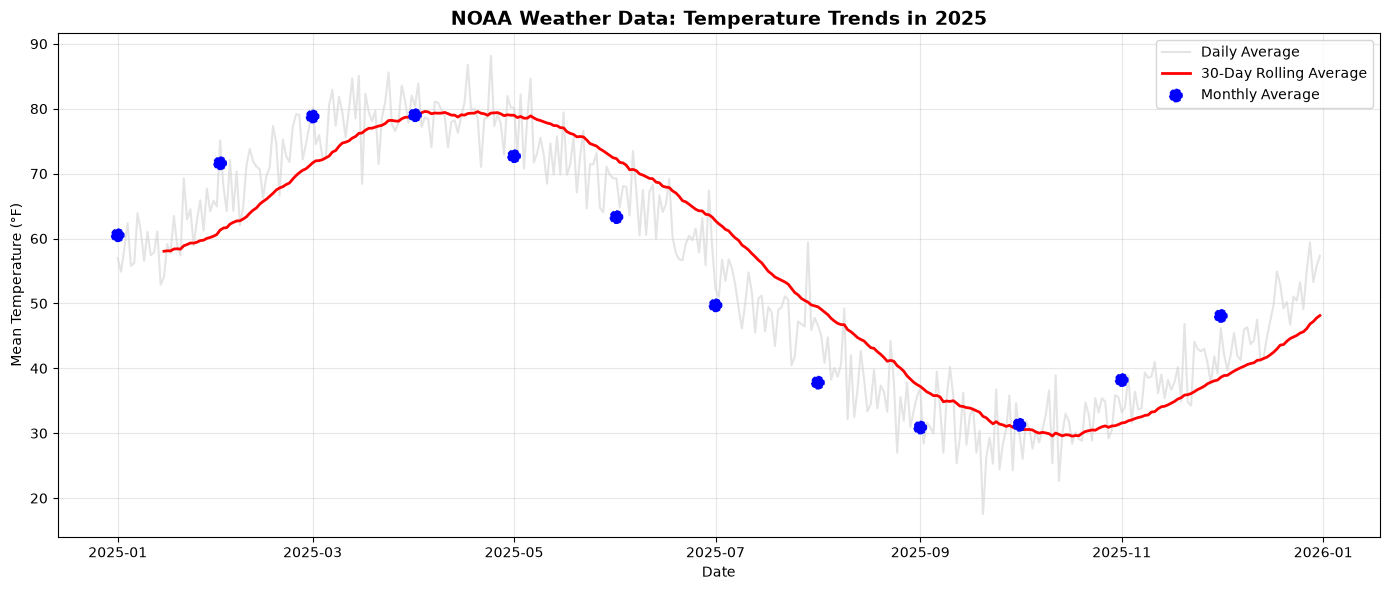

In [ ]:
#step 6
plt.figure(figsize=(14, 6))

# 1 Raw daily readings- light gray 
plt.plot(
    df_temp.index,
    df_temp['TEMP'], 
    color = 'lightgray',
    label="Daily Average",
    alpha=0.6
)

# 2 Plot 30-day rolling average - red
plt.plot(
    df_temp.index,
    df_temp['30_day_MA'],
    color='red',
    label="30-Day Rolling Average",
    linewidth=2
)

# 3 Plot monthly averages
plt.scatter(
    monthly_avg.index,
    monthly_avg['TEMP'],
    color = 'blue',
    s=80,
    zorder =5,
    marker="o",
    linestyle="--",
    label="Monthly Average"
)

plt.title("NOAA Weather Data: Temperature Trends in 2025", fontsize = 14, fontweight = 'bold')
plt.xlabel("Date")
plt.ylabel("Mean Temperature (°F)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()